In [70]:
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

In [71]:
df = pd.read_csv("Social_Network_Ads.csv")
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [72]:
df.shape

(400, 5)

In [73]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   User ID          400 non-null    int64 
 1   Gender           400 non-null    object
 2   Age              400 non-null    int64 
 3   EstimatedSalary  400 non-null    int64 
 4   Purchased        400 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 15.8+ KB


In [74]:
df.isna().sum()

User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64

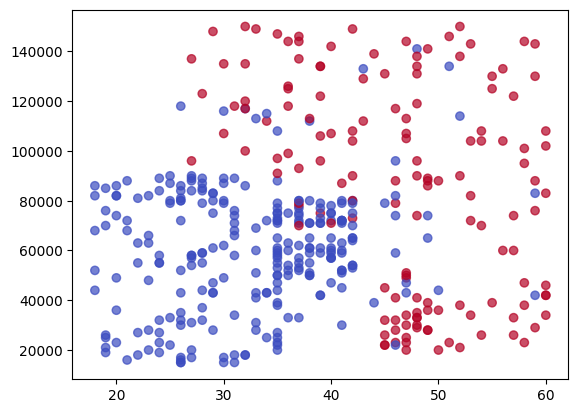

In [75]:
# sns.scatterplot(data = df, x = "Age", y = "EstimatedSalary")
plt.scatter(df["Age"], df["EstimatedSalary"],
            c=df["Purchased"], cmap="coolwarm", alpha=0.7)

In [76]:
X = df[["Age", "EstimatedSalary"]]
y = df["Purchased"]

In [77]:
print(X.shape)
print(y.shape)

(400, 2)
(400,)


In [78]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=666)

In [79]:
base_mod = DecisionTreeClassifier(random_state=42)
base_mod.fit(X_train, y_train)

print("Baseline Accuracy: ", round(base_mod.score(X_train, y_train), 3))
print("Tree Depth: ", base_mod.get_depth())
print("Number of leaves: ", base_mod.get_n_leaves())

Baseline Accuracy:  0.994
Tree Depth:  12
Number of leaves:  49


In [80]:
base_scores = cross_val_score(
    base_mod, X_train, y_train, cv = 5, scoring="accuracy"
)

print("Accuracy for each fold: ", base_scores.round(3))
print("Mean Accuracy for Base model: ", round(base_scores.mean(), 3))

Accuracy for each fold:  [0.891 0.844 0.875 0.859 0.891]
Mean Accuracy for Base model:  0.872


In [81]:
param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [2,3,4,5,None],
    "min_samples_leaf": [1,2,4,6]
}

In [82]:
grid = GridSearchCV(
    DecisionTreeClassifier(random_state=666),
    param_grid=param_grid,
    scoring = "accuracy",
    cv = 5,
    return_train_score=True,
    refit=True,
    n_jobs = 1
)

In [83]:
grid.fit(X_train, y_train)
print("Best Parameters: ", grid.best_params_)
print("Best CV Mean Accuracy: ", round(grid.best_score_,3))

Best Parameters:  {'criterion': 'gini', 'max_depth': 2, 'min_samples_leaf': 1}
Best CV Mean Accuracy:  0.922


In [86]:
res = pd.DataFrame(grid.cv_results_)
columns = ["param_criterion", "param_max_depth", "param_min_samples_leaf", "mean_train_score", "mean_test_score"]
display(res[columns].sort_values("mean_test_score", ascending=False).head(10).round(3))

,param_criterion,param_max_depth,param_min_samples_leaf,mean_train_score,mean_test_score
0,gini,2,1,0.925,0.922
1,gini,2,2,0.925,0.922
2,gini,2,4,0.925,0.922
3,gini,2,6,0.925,0.922
7,gini,3,6,0.925,0.922
22,entropy,2,4,0.925,0.922
21,entropy,2,2,0.925,0.922
20,entropy,2,1,0.925,0.922
27,entropy,3,6,0.925,0.922
23,entropy,2,6,0.925,0.922


In [87]:
best_tree = grid.best_estimator_

print("Best Tree Depth: ", best_tree.get_depth())
print("Best Tree Leaves: ", best_tree.get_n_leaves())

Best Tree Depth:  2
Best Tree Leaves:  4


[Text(0.5, 0.8333333333333334, 'Age <= 43.5\ngini = 0.464\nsamples = 320\nvalue = [203, 117]'),
 Text(0.25, 0.5, 'EstimatedSalary <= 90500.0\ngini = 0.283\nsamples = 234\nvalue = [194, 40]'),
 Text(0.375, 0.6666666666666667, 'True  '),
 Text(0.125, 0.16666666666666666, 'gini = 0.07\nsamples = 193\nvalue = [186.0, 7.0]'),
 Text(0.375, 0.16666666666666666, 'gini = 0.314\nsamples = 41\nvalue = [8, 33]'),
 Text(0.75, 0.5, 'Age <= 47.5\ngini = 0.187\nsamples = 86\nvalue = [9, 77]'),
 Text(0.625, 0.6666666666666667, '  False'),
 Text(0.625, 0.16666666666666666, 'gini = 0.375\nsamples = 24\nvalue = [6, 18]'),
 Text(0.875, 0.16666666666666666, 'gini = 0.092\nsamples = 62\nvalue = [3, 59]')]

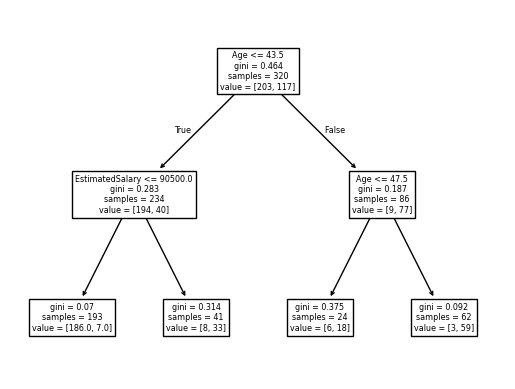

In [89]:
plot_tree(best_tree, feature_names=X.columns)

In [90]:
y_pred = best_tree.predict(X_test)
print("Test Accuracy: ", round(accuracy_score(y_test, y_pred),3))

Test Accuracy:  0.875


In [91]:
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names = ["No Purchase", "Purchased"]))


Classification report:
              precision    recall  f1-score   support

 No Purchase       0.96      0.85      0.90        54
   Purchased       0.75      0.92      0.83        26

    accuracy                           0.88        80
   macro avg       0.85      0.89      0.86        80
weighted avg       0.89      0.88      0.88        80



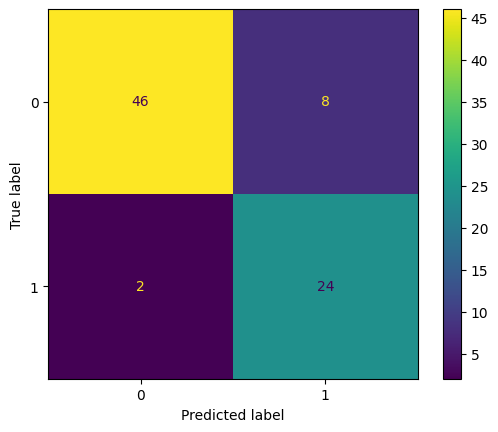

In [92]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)

In [111]:
new = pd.DataFrame({"Age": [42], "EstimatedSalary": [90501]})
pred = best_tree.predict(new)[0]
prob = best_tree.predict_proba(new)[0]

print("Prediction for new person: ", pred)
print("Prediction probabilities of result: ", prob.round(3))

Prediction for new person:  1
Prediction probabilities of result:  [0.195 0.805]
